<a href="https://colab.research.google.com/github/rania04286-r/cv-license-plate-detection/blob/main/02_duplicate_check.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02. Duplicate and leakage check


**What this does, in plain words**
1. Copies the dataset from Drive to Colab's own disk (faster to read; a few minutes).
2. Lists every image and reads its annotation file.
3. Gives each image a short "fingerprint", so near-copies (brighter, resized, flipped) get almost the same one.
4. Puts look-alike images into the same **group**.
5. Shows how many of Roboflow's *test* images have a twin in its *train/valid* folders. This is the leakage number for our proposal.
6. Builds **our own** train / val / test split where a group never lands in two splits.
7. Saves `manifest.csv` to `CV_Team_Project/outputs`. The next notebook (03) needs it.

## 1. Settings and fast copy of the data

In [1]:
from pathlib import Path
import shutil
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

try:                                      # connect Google Drive (only works inside Colab)
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

TEAM = Path("/content/drive/MyDrive/CV_Team_Project")
DRIVE_DATA = TEAM / "dataset" / "extracted"      # your extracted dataset: train/ valid/ test/
LOCAL_DATA = Path("/content/data")               # fast copy on Colab's own disk (wiped when the session ends)
OUT_DIR = TEAM / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_BITS = 8   # two photos that differ in <= 8 of the 64 fingerprint bits count as "the same photo"
SEED = 42      # keep fixed so everyone gets the same split

# What your own earlier check found (images, plates). We compare against it below.
EXPECTED = {"train": (7057, 7357), "valid": (2048, 2195), "test": (1020, 1085)}


def copy_tree_fast(src, dst, workers=16):
    files = [p for p in src.rglob("*") if p.is_file()]
    def one(p):
        t = dst / p.relative_to(src)
        t.parent.mkdir(parents=True, exist_ok=True)
        if not t.exists():
            shutil.copyfile(p, t)
    with ThreadPoolExecutor(workers) as ex:
        list(tqdm(ex.map(one, files), total=len(files), desc="copying"))

if not (LOCAL_DATA / "train").exists():
    print("Copying the dataset to Colab's disk. This takes a few minutes, once per session.")
    copy_tree_fast(DRIVE_DATA, LOCAL_DATA)
DATA_DIR = LOCAL_DATA
print("data folder:", DATA_DIR, "| contains:", sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir()))

Mounted at /content/drive
Copying the dataset to Colab's disk. This takes a few minutes, once per session.


copying:   0%|          | 0/20252 [00:00<?, ?it/s]

data folder: /content/data | contains: ['test', 'train', 'valid']


## 2. List the images and read the annotations

In [2]:
!pip install -q imagehash
import json
import xml.etree.ElementTree as ET
import pandas as pd

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
rows, missing_xml = [], 0
for split_dir in ["train", "valid", "test"]:
    for img in sorted(p for p in (DATA_DIR / split_dir).rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT):
        xml = img.with_suffix(".xml")
        w = h = None
        boxes = []
        if xml.exists():
            root = ET.parse(xml).getroot()
            w, h = int(root.find("size/width").text), int(root.find("size/height").text)
            for obj in root.findall("object"):
                b = obj.find("bndbox")
                boxes.append([int(float(b.find(t).text)) for t in ("xmin", "ymin", "xmax", "ymax")])
        else:
            missing_xml += 1
        rows.append(dict(image=img.name, rel_path=img.relative_to(DATA_DIR).as_posix(), xml=xml.name if xml.exists() else None,
                         width=w, height=h, n_boxes=len(boxes), boxes=json.dumps(boxes), roboflow_split=split_dir))
df = pd.DataFrame(rows)
df["path"] = [DATA_DIR / p for p in df["rel_path"]]

found = df.groupby("roboflow_split").agg(images=("image", "count"), plates=("n_boxes", "sum"))
print(found.to_string())
print("images without an XML file:", missing_xml)
for s, (ni, npl) in EXPECTED.items():
    ok = (s in found.index) and found.loc[s, "images"] == ni and found.loc[s, "plates"] == npl
    print(f"{s:6s} matches your earlier check ({ni} images, {npl} plates):", "YES" if ok else "NO, tell the team before continuing")

                images  plates
roboflow_split                
test              1020    1085
train             7057    7357
valid             2048    2195
images without an XML file: 0
train  matches your earlier check (7057 images, 7357 plates): YES
valid  matches your earlier check (2048 images, 2195 plates): YES
test   matches your earlier check (1020 images, 1085 plates): YES


## 3. Fingerprint every image (also of its mirror image, to catch flipped copies)

In [3]:
import numpy as np, imagehash
from PIL import Image, ImageOps

def bits(im):
    return imagehash.dhash(im).hash.flatten().astype(np.float32)   # 64 yes/no values

H, HF = [], []
for p in tqdm(df["path"], desc="fingerprints"):
    im = Image.open(p).convert("RGB")
    H.append(bits(im))
    HF.append(bits(ImageOps.mirror(im)))
H, HF = np.array(H), np.array(HF)
print("fingerprints:", H.shape)

fingerprints:   0%|          | 0/10125 [00:00<?, ?it/s]

fingerprints: (10125, 64)


## 4. Group look-alikes
Images whose fingerprints differ in at most `MAX_BITS` bits (of 64), directly or through a chain of matches, share a group.
If that makes one giant group (a sign the setting is too loose for this dataset), the cell automatically tries stricter settings and tells you which one it used.

In [4]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

def diff_bits(A, B):                      # number of differing bits for every pair
    return A @ (1 - B).T + (1 - A) @ B.T

ii, jj, dd = [], [], []
for s in range(0, len(H), 1000):          # blocks keep memory small
    d = np.minimum(diff_bits(H[s:s+1000], H), diff_bits(H[s:s+1000], HF))   # also matches mirrored copies
    i, j = np.where(d <= MAX_BITS)
    ii.append(i + s); jj.append(j); dd.append(d[i, j])
ii, jj, dd = np.concatenate(ii), np.concatenate(jj), np.concatenate(dd)
n = len(H)

def make_groups(limit):
    keep = dd <= limit
    return connected_components(coo_matrix((np.ones(keep.sum()), (ii[keep], jj[keep])), shape=(n, n)), directed=False)

BIG = max(100, n // 100)                  # a group bigger than this is not "one photo and its copies"
tried = []
for limit in [MAX_BITS] + [b for b in (6, 5, 4, 3, 2, 1, 0) if b < MAX_BITS]:
    n_groups, group = make_groups(limit)
    largest = int(np.bincount(group).max())
    tried.append(dict(MAX_BITS=limit, groups=n_groups, largest_group=largest))
    if largest <= BIG:
        break
MAX_BITS_USED = limit
df["group"] = group
print(pd.DataFrame(tried).to_string(index=False))
if MAX_BITS_USED != MAX_BITS:
    print(f"\nMAX_BITS={MAX_BITS} made one giant group, so MAX_BITS_USED={MAX_BITS_USED} was used instead. Report this number.")

sizes = df.groupby("group").size()
summary = pd.Series({
    "MAX_BITS used": MAX_BITS_USED,
    "images": n,
    "groups": n_groups,
    "images in a group of 2 or more": int((df["group"].map(sizes) >= 2).sum()),
    "largest group": int(sizes.max()),
})
print()
print(summary.to_string())

 MAX_BITS  groups  largest_group
        8    5167           2164
        6    6620            907
        5    7377            605
        4    8102            168
        3    8727             76

MAX_BITS=8 made one giant group, so MAX_BITS_USED=3 was used instead. Report this number.

MAX_BITS used                         3
images                            10125
groups                             8727
images in a group of 2 or more     2310
largest group                        76


## 5. The leakage number: does Roboflow's own test set overlap its train/valid?

In [5]:
by = df.groupby(["group", "roboflow_split"]).size().unstack(fill_value=0)
for col in ["train", "valid", "test"]:
    if col not in by:
        by[col] = 0
twin_elsewhere = (by["train"] + by["valid"]).reindex(df["group"]).values > 0
test_mask = (df["roboflow_split"] == "test").values
n_leaky = int((test_mask & twin_elsewhere).sum())
print(f"Roboflow test images with a look-alike in its train/valid folders: {n_leaky} of {test_mask.sum()} "
      f"({100 * n_leaky / test_mask.sum():.1f}%)")

Roboflow test images with a look-alike in its train/valid folders: 219 of 1020 (21.5%)


## 6. Look at examples with your own eyes
Each row is one group that spans Roboflow's test and train/valid folders. Are they really the same photo? If most are **not**, set `MAX_BITS` lower (settings cell, try 5) and rerun from step 4. If obvious copies are missing, raise it a little (try 10) and check again.

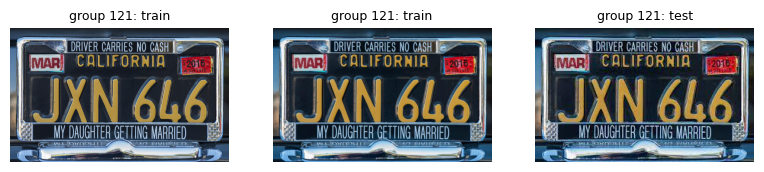

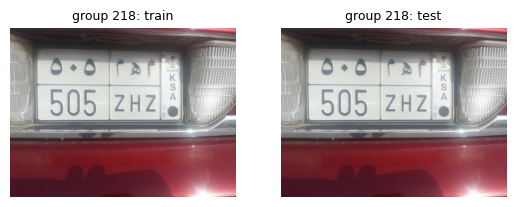

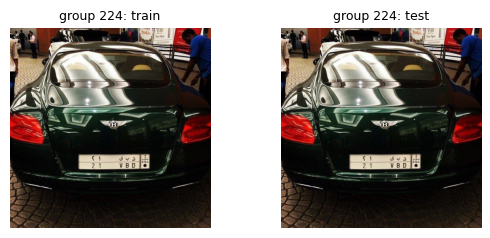

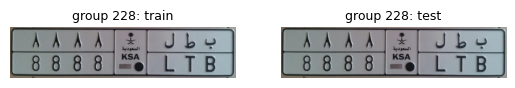

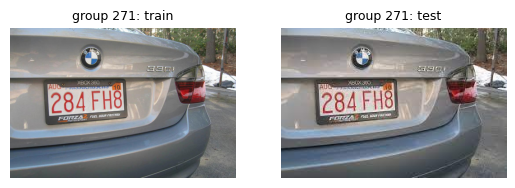

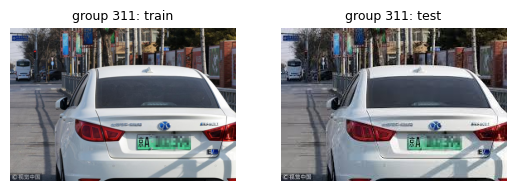

In [6]:
import matplotlib.pyplot as plt

cross = by[(by["test"] > 0) & ((by["train"] + by["valid"]) > 0)].index[:6]
for g in cross:
    members = df[df["group"] == g].head(4)
    fig, axes = plt.subplots(1, len(members), figsize=(3.2 * len(members), 2.6))
    axes = np.atleast_1d(axes)
    for ax, (_, r) in zip(axes, members.iterrows()):
        ax.imshow(Image.open(r["path"]).convert("RGB")); ax.axis("off")
        ax.set_title(f"group {g}: {r['roboflow_split']}", fontsize=9)
    plt.show()
if len(cross) == 0:
    print("No groups span test and train/valid at this threshold.")

## 7. Our own split: whole groups only
About 70% train, 15% validation, 15% test. A group never lands in two splits.

In [7]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_idx = next(gss.split(df, groups=df["group"]))
rest = df.iloc[trainval_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED)
tr, va = next(gss2.split(rest, groups=rest["group"]))

df["split"] = "test"
df.loc[rest.index[tr], "split"] = "train"
df.loc[rest.index[va], "split"] = "val"

assert df.groupby("group")["split"].nunique().max() == 1, "a group was split across partitions"
print("OK: no group appears in two splits")
df.groupby("split").agg(images=("image", "count"), groups=("group", "nunique"), plates=("n_boxes", "sum"))

OK: no group appears in two splits


,images,groups,plates
split,,,
test,1496,1310,1591
train,7165,6108,7498
val,1464,1309,1548


## 8. Save the manifest

In [8]:
manifest = df[["image", "rel_path", "xml", "width", "height", "n_boxes", "boxes", "group", "split", "roboflow_split"]]
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)
print("saved", OUT_DIR / "manifest.csv", "with", len(manifest), "rows")

saved /content/drive/MyDrive/CV_Team_Project/outputs/manifest.csv with 10125 rows
